In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sunsim import *

from astropy import units as u
from specutils import Spectrum1D
from specutils.manipulation import FluxConservingResampler
import scipy.integrate as integrate




In [2]:
##### Parameters #####

N_rings = 10
ccf_mask = None
instrument = None
rv_ccf = None
inclination = 90 #np.deg2rad(7.25)
rotation_period = 24.47
stellar_radius = 1                                        
stellar_mass = 1                                   
logg = 4.4  
differential_rotation = 0     
simulate_planet = False
time = np.linspace(0,25, 50)
spot_dT = 500
T_quiet = 5770

mask_path = '/Users/sophiestucki/starsim/starsim/masks/HARPS_G20_mps_friendly.mas'

rotation_in_spectra = False

# fluxes
flux_quiet = np.load('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/MPS-ATLAS spectra/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_quiet_low = np.load('/Users/sophiestucki/Documents/poet/mps/av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', allow_pickle=True).item()


flux_fc = np.load('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/MPS-ATLAS spectra/av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_fc_low = np.load('/Users/sophiestucki/Documents/poet/mps/av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', allow_pickle=True).item()
flux_sp =  np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_sp_low =  np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_PHOENIX_low_res_specint_grid.npy', allow_pickle=True).item()

for mu in flux_sp.keys():
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], (T_quiet-spot_dT)) / black_body(flux_sp[mu]['wav'], T_quiet) 
    flux_sp_low[mu]['intensity'] *= black_body(flux_sp_low[mu]['wav'], (T_quiet-spot_dT)) / black_body(flux_sp_low[mu]['wav'], T_quiet) 
    flux_sp_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10) / 1e12
    flux_quiet_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10)/ 1e12
    flux_fc_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10)/ 1e12
    

rv_grid = np.arange(-18000,1825,25)
wvm, fm = mask_weights(mask_path)

# CCFs >TODO: CCF function ç
ccf_quiet = CCF_grid(N_rings, flux_quiet, rv_grid, wvm, fm, convective_blueshift=0)
ccf_fc = CCF_grid(N_rings, flux_fc, rv_grid, wvm, fm, convective_blueshift=0)
# ccf_sp = CCF_grid(N_rings, flux_quiet, rv_grid, wvm, fm, convective_blueshift=0)

# Grids 
# flux_grid_quiet_spec = flux_grid(N_rings, flux_quiet, 'quiet', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius, stellar_rotation=False, mode='spectroscopy')
# flux_grid_quiet_spec.built_grid()

# flux_grid_quiet_rot = flux_grid(N_rings, flux_quiet, 'quiet', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius, stellar_rotation=True, mode='spectroscopy')
# flux_grid_quiet_rot.built_grid()


High resolution disk-integrated spectrum

In [3]:
# rot_disk_integrated = np.sum(flux_grid_quiet_rot.grid, axis=0)
# disk_integrated = np.sum(flux_grid_quiet_spec.grid, axis=0)

# plt.plot(flux_grid_quiet_rot.wv, rot_disk_integrated / ( 1e-8 * flux_grid_quiet_rot.wv**2 * 2.99792458e10)/flux_grid_quiet_rot.total_brightness, label='rotating')
# plt.plot(flux_grid_quiet_spec.wv, disk_integrated / ( 1e-8 * flux_grid_quiet_spec.wv**2 * 2.99792458e10)/flux_grid_quiet_spec.total_brightness, label='rest frame')
# plt.xlim(5000.25,5001.2)
# plt.legend()
# plt.show()

Active regions

In [4]:
##### List #####
spot = active_region('sp', 10, 90, 180)
active_regions_map = [spot]

Photometry

In [5]:
N_rings = 60

flux_grid_quiet = flux_grid(N_rings, flux_quiet_low, 'quiet', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
flux_grid_quiet.built_grid()

flux_grid_fc = flux_grid(N_rings, flux_fc_low, 'fc', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
flux_grid_fc.built_grid()

flux_grid_sp = flux_grid(N_rings, flux_sp_low, 'sp', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
flux_grid_sp.built_grid()

In [6]:
ss = StarSim(time,N_rings , 0, 25, 0, active_regions_map, flux_grid_quiet.total_brightness, flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid,  mode='photometry')
ss.generate_timeseries()

Date 25.0. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [50/50]%00%. [49/50]%%

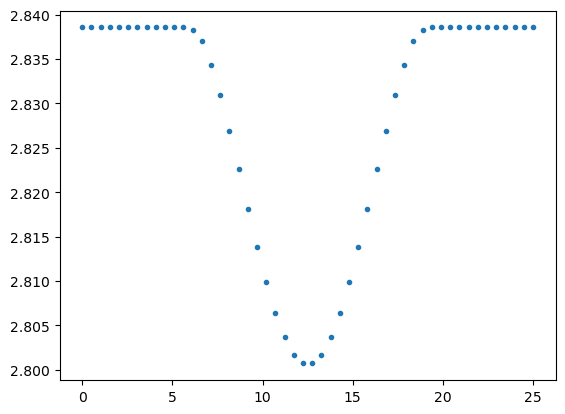

In [7]:
plt.plot(ss.obs_times, ss.flux_var, '.')
plt.show()


In [8]:
fac = active_region('fc', 10, 90, 180)
active_regions_map = [fac]

ss = StarSim(time,N_rings , 0, 25, 0, active_regions_map, flux_grid_quiet.total_brightness, flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid,  mode='photometry')
ss.generate_timeseries()

Date 25.0. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [50/50]%00%. [49/50]%%

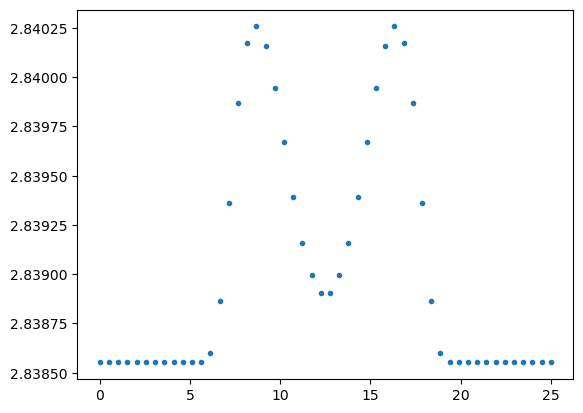

In [9]:
plt.plot(ss.obs_times, ss.flux_var, '.')
plt.show()